In [1]:
# Импорт библиотек и инициализация директорий, в которых хранятся данные
import os
import cv2
import time
import pandas as pd
import numpy as np
import json

from PIL import Image
import torch
import torchvision
import torchvision.transforms as T

from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torch.utils.data import DataLoader, Dataset

import seaborn as sns
import matplotlib.pyplot as plt
from tqdm import tqdm


train_path = "C:/Users/admin/Downloads/archive/train_dataset/train_images/"
test_path = "C:/Users/admin/Downloads/archive/test_dataset/test_images/"

In [2]:
# Извлечение данных из json файла
with open("C:/Users/admin/Downloads/archive/train_dataset/train.json") as f:
    data_dict = json.load(f)

data = []

for annotation in data_dict['annotations']:
    filename = annotation['filename']
    xmin = annotation['bndbox']['xmin']
    ymin = annotation['bndbox']['ymin']
    xmax = annotation['bndbox']['xmax']
    ymax = annotation['bndbox']['ymax']

    if annotation['inbox']:
        for inbox in annotation['inbox']:
            color = inbox['color']
            data.append({
                    'filename': filename,
                    'xmin': xmin,
                    'ymin': ymin,
                    'xmax': xmax,
                    'ymax': ymax,
                    'color': color,
                })


df = pd.DataFrame(data)
df.to_csv('traffic_lights.csv', index=False)

In [3]:
data_tf = pd.read_csv('C:/Users/admin/Documents/мирэа/Geom_mod/traffic_lights.csv')

In [4]:
data_tf['filename'] = data_tf['filename'].str.replace('train_images\\\\', '', regex=True)
data_tf.to_csv('traffic_lights_labels.csv', index=False)

In [5]:
df = pd.read_csv('C:/Users/admin/Documents/мирэа/Geom_mod/traffic_lights_labels.csv')
df.head()

,filename,xmin,ymin,xmax,ymax,color
0,00001.jpg,1026.5,741.8,1077.5,910.9,red
1,00002.jpg,1418.7,1136.8,1428.3,1149.4,red
2,00003.jpg,2574.3,868.7,2632.3,887.1,red
3,00003.jpg,2252.1,899.6,2300.8,918.7,green
4,00004.jpg,833.3,1163.2,843.6,1184.8,green


In [6]:
unq_values = df["filename"].unique()
print("Всего светофоров: ", len(df))
print("Уникальных изображений: ",len(unq_values))

Всего светофоров:  9422
Уникальных изображений:  2470


In [7]:
classes = df["color"].unique()
print("\nКлассы: \n", *classes)


Классы: 
 red green yellow


C:\Users\admin\AppData\Local\Temp\ipykernel_72128\805909503.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="color", data=df, palette=colors_palette)


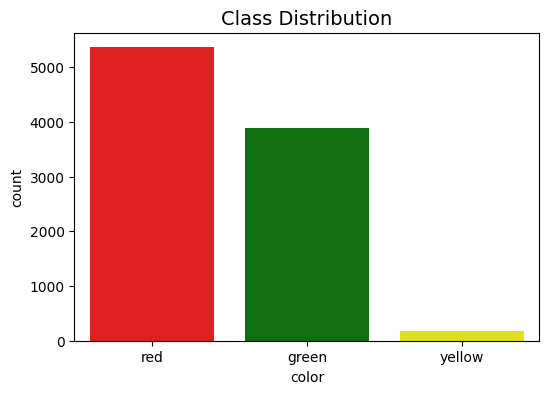

In [8]:
colors_palette = {'red': 'red', 'green': 'green', 'yellow': 'yellow'}
plt.figure(figsize=(6, 4))
plt.title('Class Distribution', fontsize=14)
sns.countplot(x="color", data=df, palette=colors_palette)
plt.show()

In [9]:
def plot_img(image_name, data_path, df):
    fig, ax = plt.subplots(2, 1, figsize=(14, 14))
    ax = ax.flatten()

    bbox = df[df['filename'] == image_name]
    img_path = os.path.join(data_path, image_name)

    image = cv2.imread(img_path, cv2.IMREAD_COLOR)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB).astype(np.float32)
    image /= 255.0
    image2 = image.copy()  # Создаем копию для отрисовки боксов

    ax[0].set_title('Original Image')
    ax[0].imshow(image)

    for idx, row in bbox.iterrows():
        x1 = row['xmin']
        y1 = row['ymin']
        x2 = row['xmax']
        y2 = row['ymax']
        label = row['color']

        if label == 'red':
            color = (255, 0, 0)
        elif label == 'green':
            color = (0, 255, 0)
        elif label == 'yellow':
            color = (255, 255, 0)

        cv2.rectangle(image2, (int(x1), int(y1)), (int(x2), int(y2)), color, 3)
        font = cv2.FONT_HERSHEY_SIMPLEX
        cv2.putText(image2, label, (int(x1), int(y1 - 10)), font, 1, color, 2)

    ax[1].set_title('Image with Bounding Box')
    ax[1].imshow(image2)
    ax[0].axis('off')
    ax[1].axis('off')
    plt.show()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..255.0].


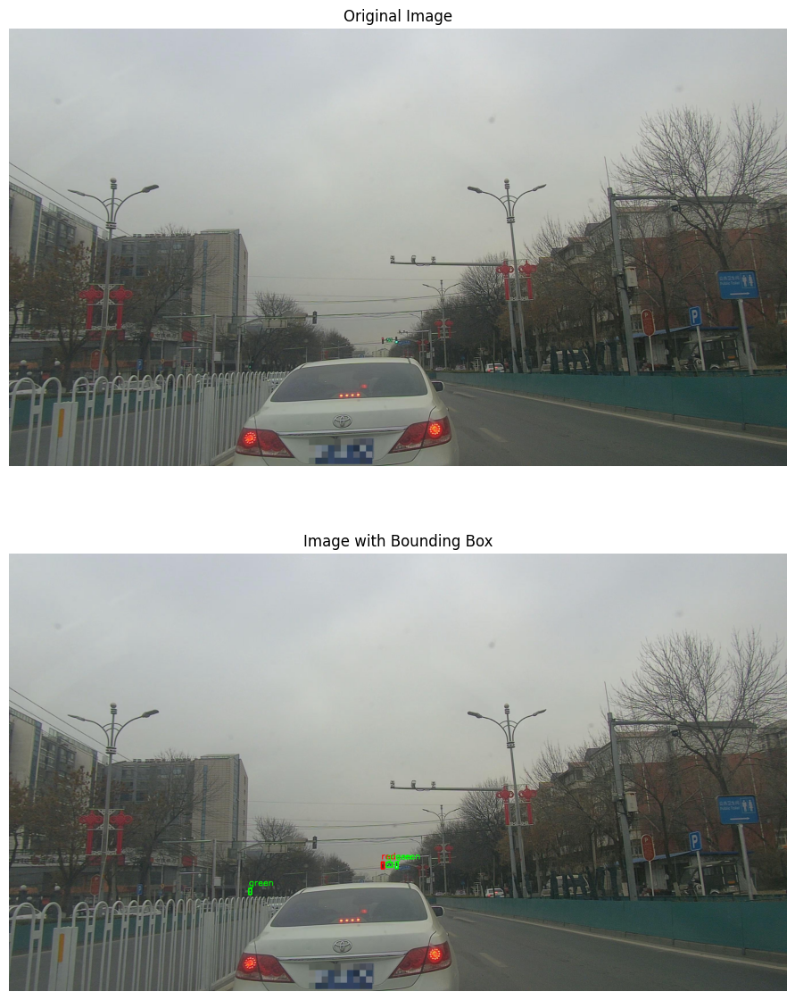

In [10]:
plot_img("00004.jpg", train_path, df)

## Подготовка набора данных для обучения

In [10]:
_classes = np.insert(classes, 0, "background", axis=0)
class_to_int = {_classes[i] : i for i in range(len(_classes))}
int_to_class = {i : _classes[i] for i in range(len(_classes))}
print("class_to_int : \n",class_to_int)
print("\nint_to_class : \n",int_to_class)

class_to_int : 
 {'background': 0, 'red': 1, 'green': 2, 'yellow': 3}

int_to_class : 
 {0: 'background', 1: 'red', 2: 'green', 3: 'yellow'}


In [11]:
class Traffic_Light_Dataset(Dataset):
    def __init__(self, dataframe, image_dir, mode='train', transforms=None, resize_factor=0.5):

        super().__init__()

        self.image_names = dataframe['filename'].unique()
        self.df = dataframe
        self.image_dir = image_dir
        self.transforms = transforms
        self.mode = mode
        self.resize_factor = resize_factor

    def __len__(self):
        return len(self.image_names)

    def __getitem__(self, index: int):
        image_name = self.image_names[index]
        records = self.df[self.df['filename'] == image_name]

        image = cv2.imread(self.image_dir + image_name, cv2.IMREAD_COLOR)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB).astype(np.float32)
        image /= 255.0

        height, width, _ = image.shape
        new_height, new_width = int(height * self.resize_factor), int(width * self.resize_factor)
        image = cv2.resize(image, (new_width, new_height))

        if self.transforms:
            image = self.transforms(image)

        if self.mode == 'train':
            boxes = records[['xmin', 'ymin', 'xmax', 'ymax']].values

            temp_labels = records[['color']].values
            labels = []
            for label in temp_labels:
                label = class_to_int[label[0]]
                labels.append(label)

            boxes = torch.as_tensor(boxes, dtype=torch.float32)
            area = (boxes[:, 3] - boxes[:, 1]) * (boxes[:, 2] - boxes[:, 0])

            target = {
                'boxes': boxes * self.resize_factor,
                'labels': torch.as_tensor(labels, dtype=torch.int64),
                'area': torch.as_tensor(area, dtype=torch.float32)
            }
            return image, target, image_name

        elif self.mode == 'test':
            return image, image_name


In [12]:
def get_transform(train=False):
    transforms = []
    transforms.append(T.ToTensor())
    if train:
        transforms.append(T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2))
    return T.Compose(transforms)

def collate_fn(batch):
    return tuple(zip(*batch))

dataset = Traffic_Light_Dataset(df, train_path, transforms=get_transform(train=True))
dataset_size = len(dataset)
train_size = int(0.8 * dataset_size)
indices = torch.randperm(dataset_size).tolist()


train_dataset = torch.utils.data.Subset(dataset, indices[:train_size])
valid_dataset = torch.utils.data.Subset(dataset, indices[train_size:])

print(f"Всего: {dataset_size}, Обучение: {len(train_dataset)}, Валидация: {len(valid_dataset)}")

train_data_loader = DataLoader(
    train_dataset,
    batch_size = 2,
    shuffle = True,
    num_workers = 2,
    collate_fn = collate_fn
)


valid_data_loader = DataLoader(
    valid_dataset,
    batch_size = 2,
    shuffle = True,
    num_workers = 0,
    collate_fn = collate_fn
)

Всего: 2470, Обучение: 1976, Валидация: 494


In [14]:
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
torch.cuda.empty_cache()

In [15]:
if torch.cuda.is_available():
    print("GPU available:", torch.cuda.is_available())
    print("Имя текущего GPU:", torch.cuda.get_device_name(0))  # Выведет название GPU
    print("Количество доступных GPU:", torch.cuda.device_count())  # Выведет количество GPU
else:
    print("GPU не доступен")

GPU не доступен


In [ ]:
model = torchvision.models.detection.fasterrcnn_resnet50_fpn(weights='DEFAULT', weights_backbone=None)
num_classes = len(class_to_int)

in_features = model.roi_heads.box_predictor.cls_score.in_features

model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:00<00:00, 208MB/s]


In [ ]:
params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.Adam(params, lr=0.0001)
# Уменьшаем LR в 10 раз каждые 5 эпох
lr_scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)
model.to(device)
epochs = 10

## Обучение модели

In [ ]:
itr = 1
total_train_loss = []
# Проходимся по эпохам
for epoch in range(epochs):
    start_time = time.time()
    train_loss = []

    # Проходимся по батчам
    for images, targets, image_names in tqdm(train_data_loader):

        # Переносим данные на GPU
        images = list(image.to(device) for image in images)
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]


        out = model(images, targets)
        losses = sum(loss for loss in out.values())
        optimizer.zero_grad()

        losses.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1)
        optimizer.step()

        loss_value = losses.item()
        train_loss.append(loss_value)

        if itr % 300 == 0:
            print(f"\n Iteration #{itr} loss: {loss_value:.4f} \n") ## {out}
        itr += 1
    lr_scheduler.step()

    epoch_train_loss = np.mean(train_loss)
    total_train_loss.append(epoch_train_loss)
    print(f'Epoch: {epoch+1}')
    print(f'Epoch train loss is {epoch_train_loss:.4f}')


    time_elapsed = time.time() - start_time
    print("Time elapsed: ",time_elapsed)

    torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'loss': epoch_train_loss
            }, f"model_{epoch}.pth")

 30%|███       | 300/988 [05:11<11:38,  1.01s/it]


 Iteration #300 loss: 0.1858 



 61%|██████    | 600/988 [10:32<06:51,  1.06s/it]


 Iteration #600 loss: 0.3841 



 91%|█████████ | 900/988 [15:48<01:18,  1.13it/s]


 Iteration #900 loss: 0.4365 



... (74 outputs left out)

 72%|███████▏  | 708/988 [07:28<02:54,  1.60it/s]


 Iteration #9600 loss: 0.1696 



100%|██████████| 988/988 [10:25<00:00,  1.58it/s]


Epoch: 10
Epoch train loss is 0.1207
Time elapsed:  625.1247184276581


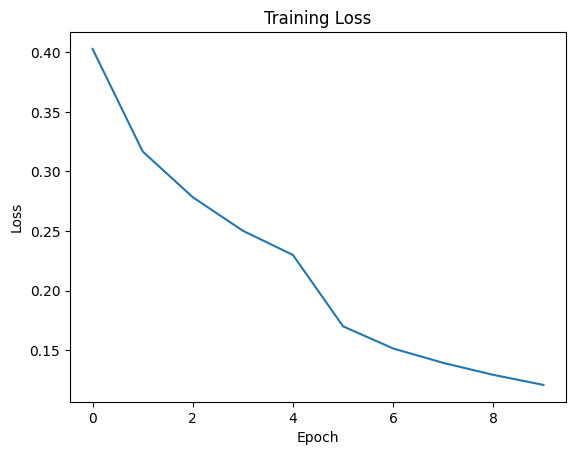

In [ ]:
plt.plot(total_train_loss)
plt.title('Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show();

In [13]:
import torch
import torchvision
import numpy as np
import cv2
import matplotlib.pyplot as plt
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

# 1. Воссоздаем словари классов (как в вашем обучении)
classes = ['red', 'green', 'yellow'] # Порядок из вашего лога обучения[cite: 1]
_classes = np.insert(classes, 0, "background", axis=0)
int_to_class = {i : _classes[i] for i in range(len(_classes))}

# 2. Инициализация архитектуры[cite: 1]
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
model = torchvision.models.detection.fasterrcnn_resnet50_fpn(weights=None)
num_classes = len(int_to_class)
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)

checkpoint_path = "model_9.pth"
checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
model.to(device)
model.eval()

print(f"Модель загружена. Эпоха: {checkpoint['epoch']+1}, Последний Loss: {checkpoint['loss']:.4f}")
print("")

Модель загружена. Эпоха: 10, Последний Loss: 0.1207



## Валидация модели

In [60]:
import torch
import numpy as np
from tqdm import tqdm
import time
from torchvision.models.detection import fasterrcnn_resnet50_fpn

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

num_classes = 4
model = fasterrcnn_resnet50_fpn(weights=None, num_classes=num_classes)
checkpoint = torch.load("model_9.pth", map_location=device, weights_only=False)

if 'model_state_dict' in checkpoint:
    model.load_state_dict(checkpoint['model_state_dict'])
else:
    model.load_state_dict(checkpoint)

model.to(device)

v_loss = []
start_time = time.time()

with torch.no_grad():
    for images, targets, image_names in tqdm(valid_data_loader, desc="Validation"):
        images = list(image.to(device) for image in images)
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
        
        model.train() 
        
        loss_dict = model(images, targets)
        losses = sum(loss for loss in loss_dict.values())
        
        loss_value = losses.item()
        v_loss.append(loss_value)

model.eval()

val_loss = np.mean(v_loss)
time_elapsed = time.time() - start_time

print(f'\n{"="*30}')
print(f'Val loss is: {val_loss:.4f}')
print(f'Time elapsed: {time_elapsed:.2f}s')
print(f'{"="*30}')

Device: cpu


Validation:   0%|          | 0/247 [00:06<?, ?it/s]


KeyboardInterrupt: 

In [27]:
folder_path = "C:/Users/admin/Downloads/archive/test_dataset/test_images/"

file_names = os.listdir(folder_path)
df_test = pd.DataFrame({'filename': file_names})

In [28]:
df_test.head()

,filename
0,00007.jpg
1,00009.jpg
2,00024.jpg
3,00035.jpg
4,00038.jpg


In [29]:
submission = pd.DataFrame(columns = ["filename", "xmin", "ymin",
                                     "xmax", "ymax", "color"])
submission.head()

,filename,xmin,ymin,xmax,ymax,color


In [14]:
images = os.listdir(test_path)

df_test = df_test.drop_duplicates(subset='filename', keep="first")

test_dataset = Traffic_Light_Dataset(df_test, test_path, mode = 'test',
                                            transforms = get_transform())

test_data_loader = DataLoader(
    test_dataset,
    batch_size=2,
    shuffle=False,
    num_workers=0,
    drop_last=False,
    collate_fn=collate_fn
)

NameError: name 'df_test' is not defined

In [33]:
threshold = 0.5
model.eval()

for images, image_names in tqdm(test_data_loader):
    images = list(image.to(device) for image in images)

    with torch.no_grad():
        outputs = model(images)

    for i, output in enumerate(outputs):
        boxes = output['boxes'].data.cpu().numpy()
        scores = output['scores'].data.cpu().numpy()
        labels = output['labels'].data.cpu().numpy()

        mask = scores >= threshold
        boxes_th = boxes[mask]
        labels_th = labels[mask]

        current_image_name = image_names[i]

        for y in range(len(boxes_th)):
            scale = 1.0 / 0.5

            x1, y1, x2, y2 = boxes_th[y] * scale
            class_name = int_to_class[labels_th[y]]

            row = pd.DataFrame([{"filename" : current_image_name,
                                 "xmin" : x1, "xmax" : x2,
                                 "ymin" : y1, "ymax" : y2,
                                 "color" : class_name}])

            submission = pd.concat([submission, row], ignore_index=True)

  0%|          | 0/200 [00:00<?, ?it/s]C:\Users\admin\AppData\Local\Temp\ipykernel_6328\1554207860.py:32: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  submission = pd.concat([submission, row], ignore_index=True)
100%|██████████| 200/200 [23:23<00:00,  7.02s/it]


In [34]:
print(submission)

       filename         xmin         ymin         xmax         ymax  color
0     00007.jpg  1254.340820   974.569153  1269.722656  1014.946045  green
1     00007.jpg  1335.489746   972.927185  1349.645508  1011.361511  green
2     00007.jpg   411.459076  1126.906494   424.681580  1160.777100    red
3     00007.jpg   390.201843  1123.733154   401.841949  1158.272095    red
4     00007.jpg  1282.581787   977.460999  1316.959473  1005.399414  green
...         ...          ...          ...          ...          ...    ...
1452  02956.jpg  2372.578369  1006.732727  2411.135010  1081.427856  green
1453  02965.jpg  2070.345947   134.486954  2203.598145   369.896729  green
1454  02965.jpg  2302.209717    89.225410  2437.471436   327.201843  green
1455  02965.jpg  2516.351318    53.942356  2672.508789   290.228149  green
1456  02975.jpg  1032.626953   951.369812  1108.244263   978.071411  green

[1457 rows x 6 columns]


In [35]:
submission.to_csv('submission.csv', index = False)

In [13]:
df = pd.read_csv('submission.csv')
df.head(15)

,filename,xmin,ymin,xmax,ymax,color
0,00007.jpg,1254.34080,974.56915,1269.72270,1014.94604,green
1,00007.jpg,1335.48970,972.92720,1349.64550,1011.36150,green
2,00007.jpg,411.45908,1126.90650,424.68158,1160.77710,red
3,00007.jpg,390.20184,1123.73320,401.84195,1158.27210,red
4,00007.jpg,1282.58180,977.46100,1316.95950,1005.39940,green
5,00007.jpg,393.11264,1126.27710,406.44318,1161.77050,red
6,00009.jpg,1831.10340,1019.44800,1844.63490,1057.29170,yellow
7,00009.jpg,1285.61610,1054.17150,1296.99570,1077.15190,yellow
8,00024.jpg,1215.34900,1083.63930,1222.47230,1103.83890,red
9,00035.jpg,1532.81640,868.25305,1552.38980,926.79500,green


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..255.0].


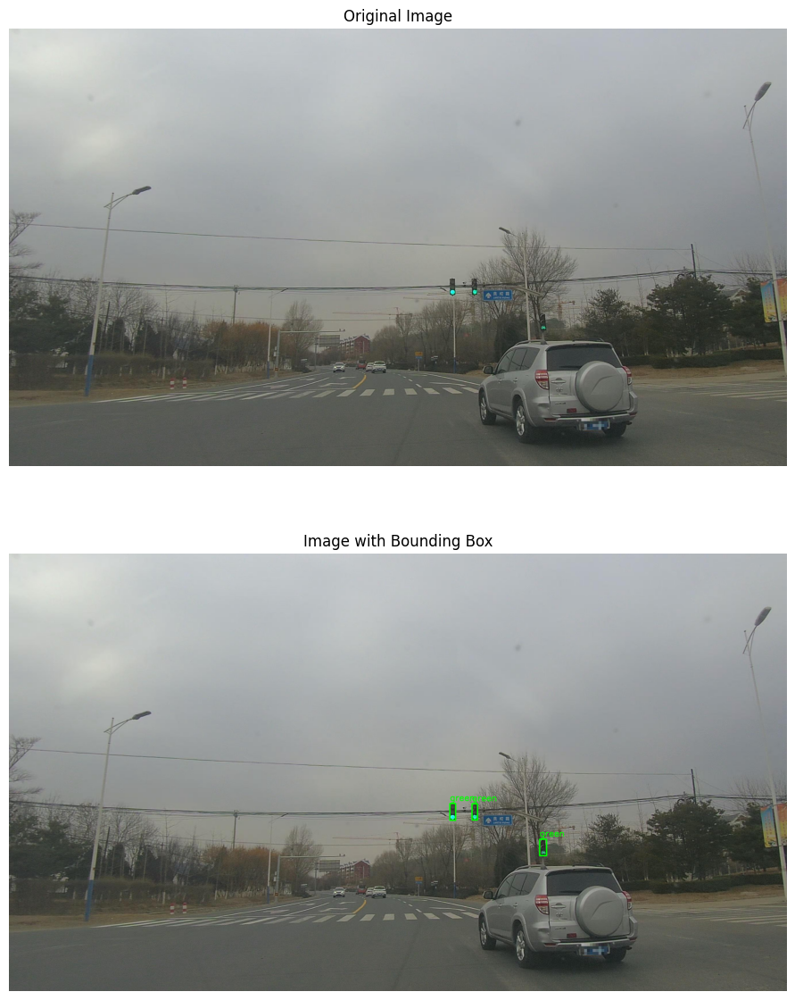

In [16]:
plot_img('00035.jpg', test_path, df)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..255.0].


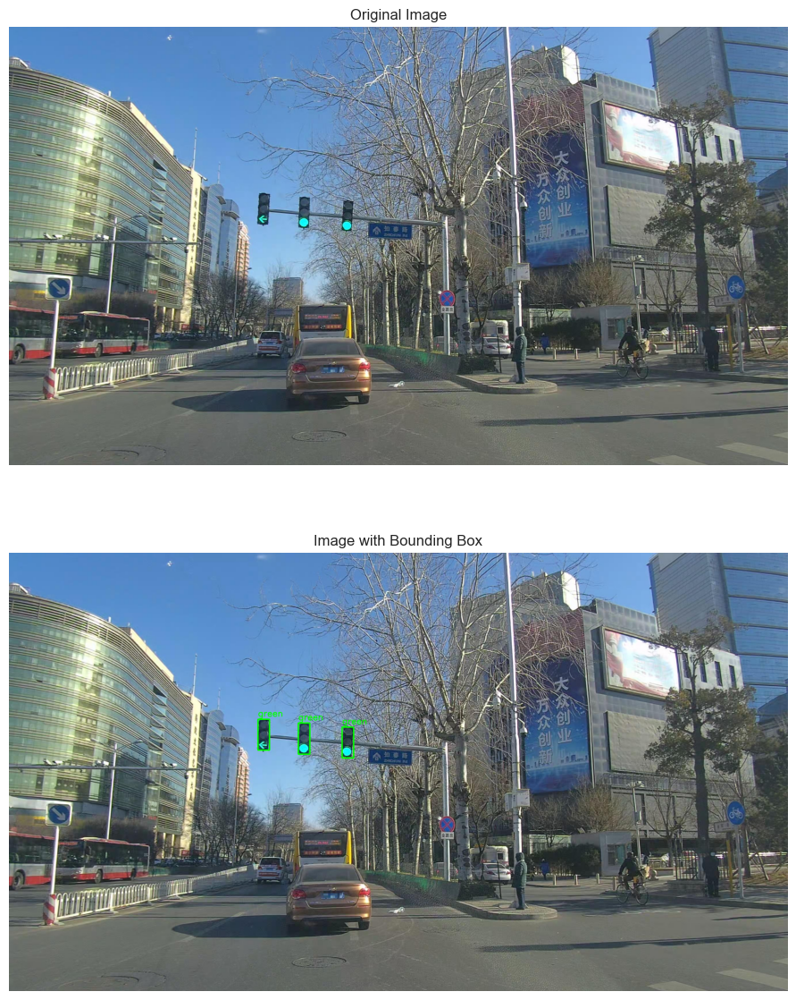

In [ ]:
plot_img('00074.jpg', test_path, df)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..255.0].


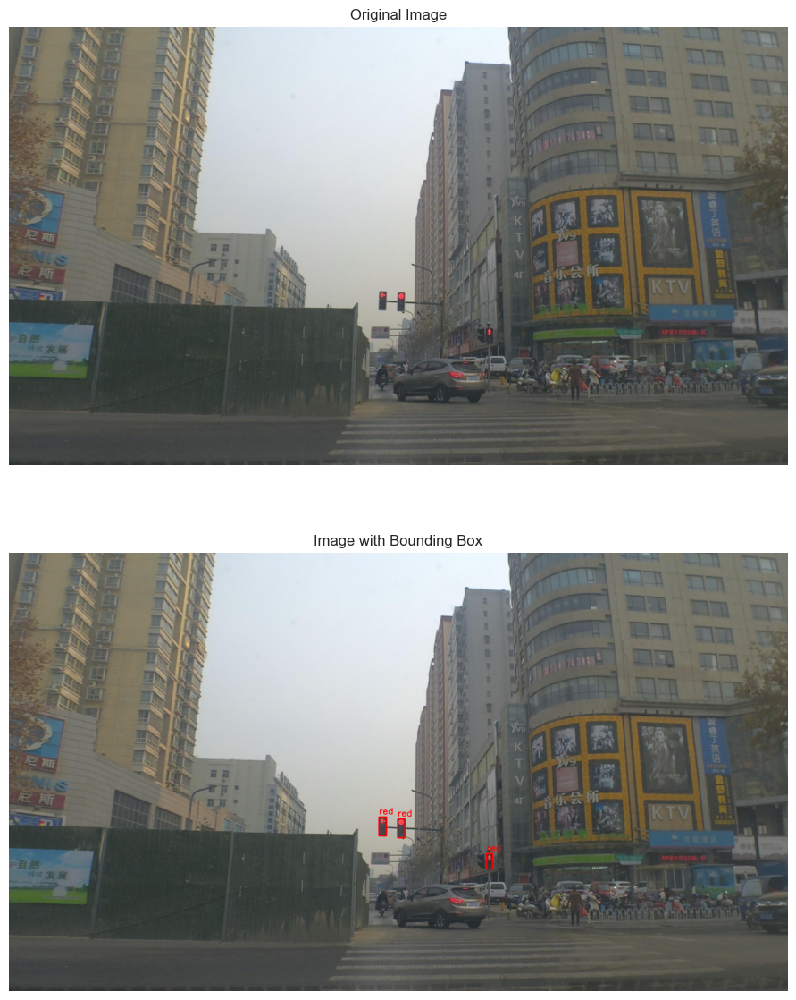

In [94]:
plot_img('02728.jpg', test_path, df)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..255.0].


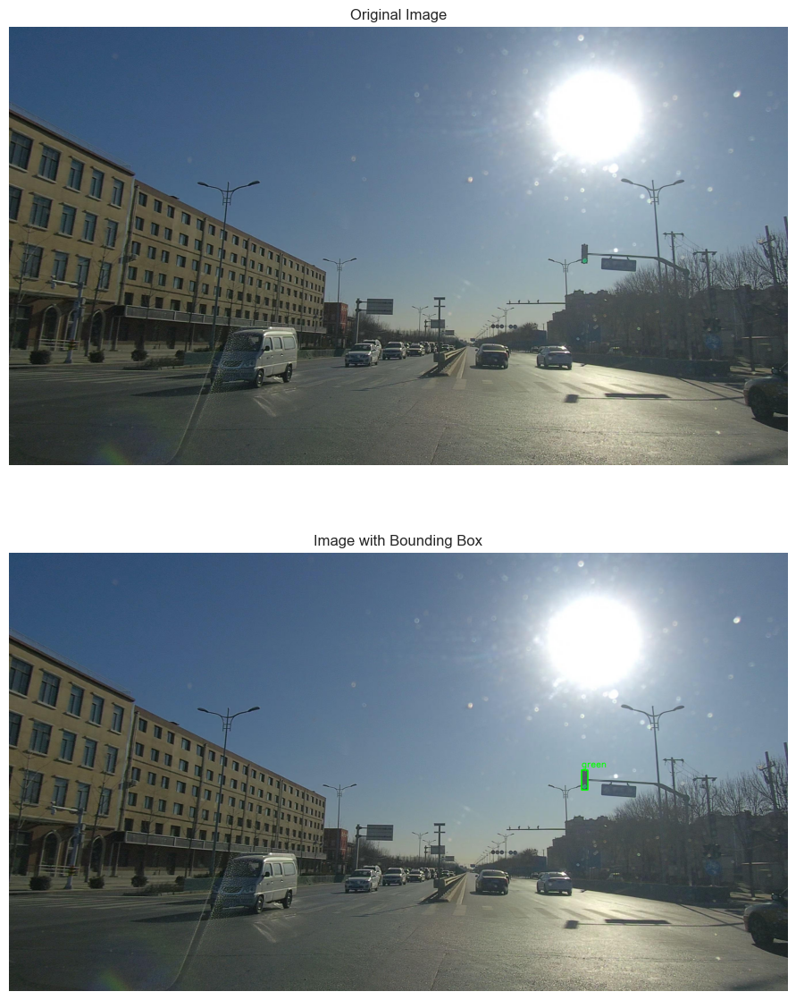

In [74]:
plot_img('00105.jpg', test_path, df)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..255.0].


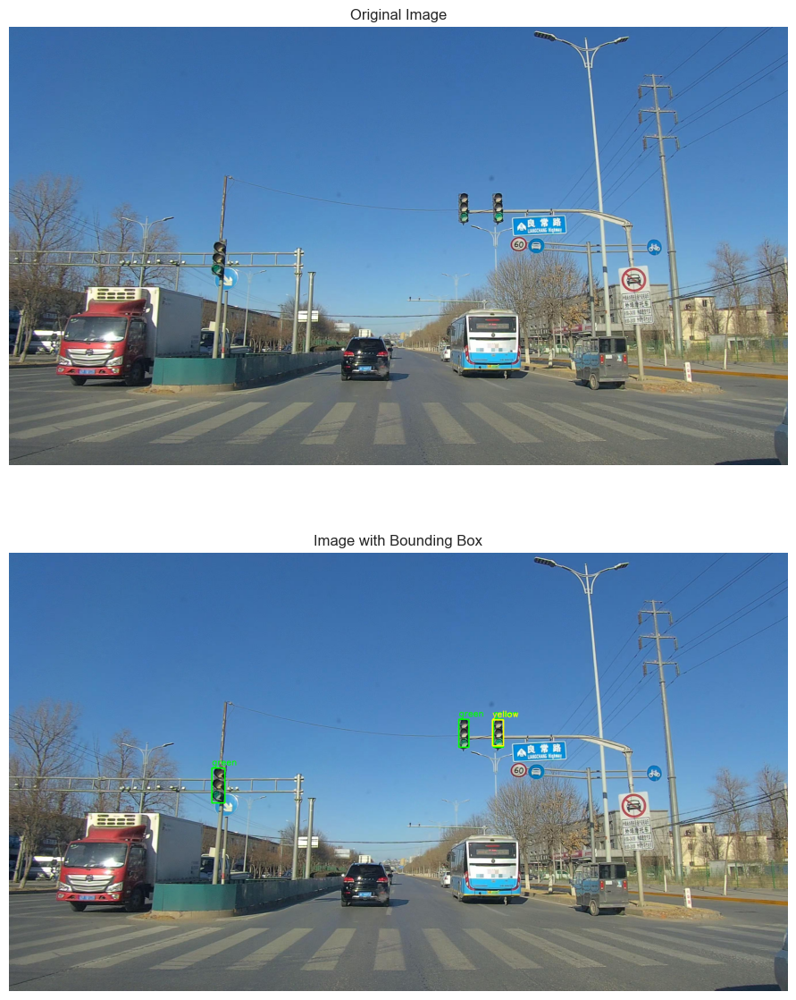

In [75]:
plot_img('00112.jpg', test_path, df)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..255.0].


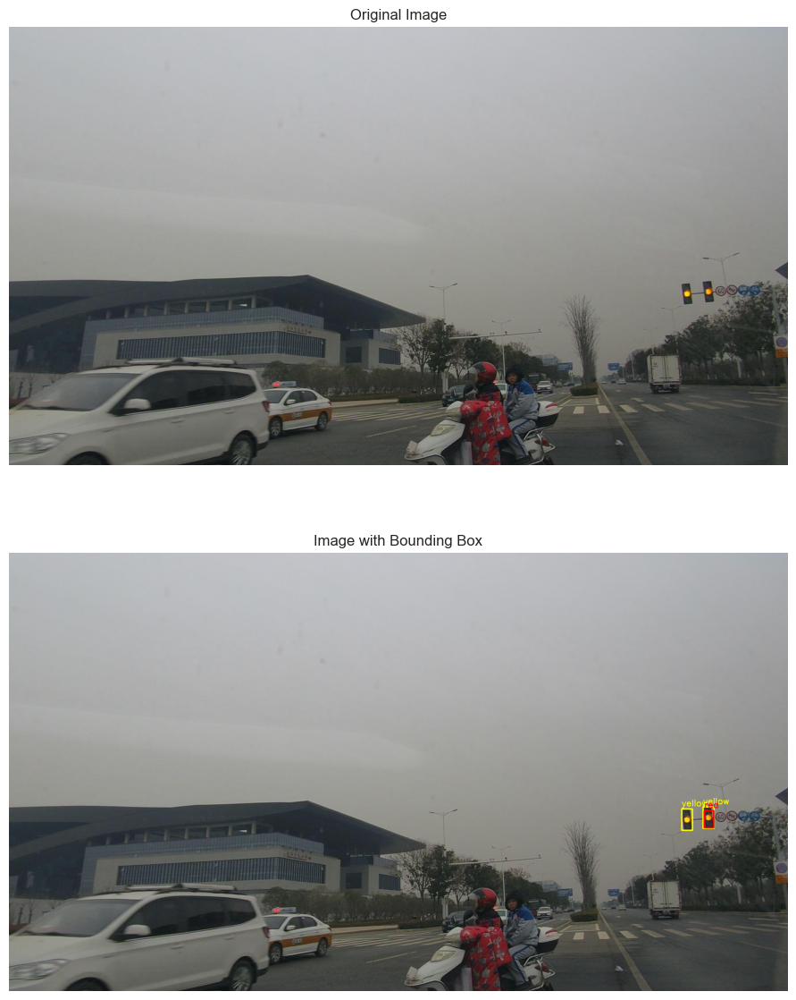

In [76]:
plot_img("02924.jpg", test_path, df)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..255.0].


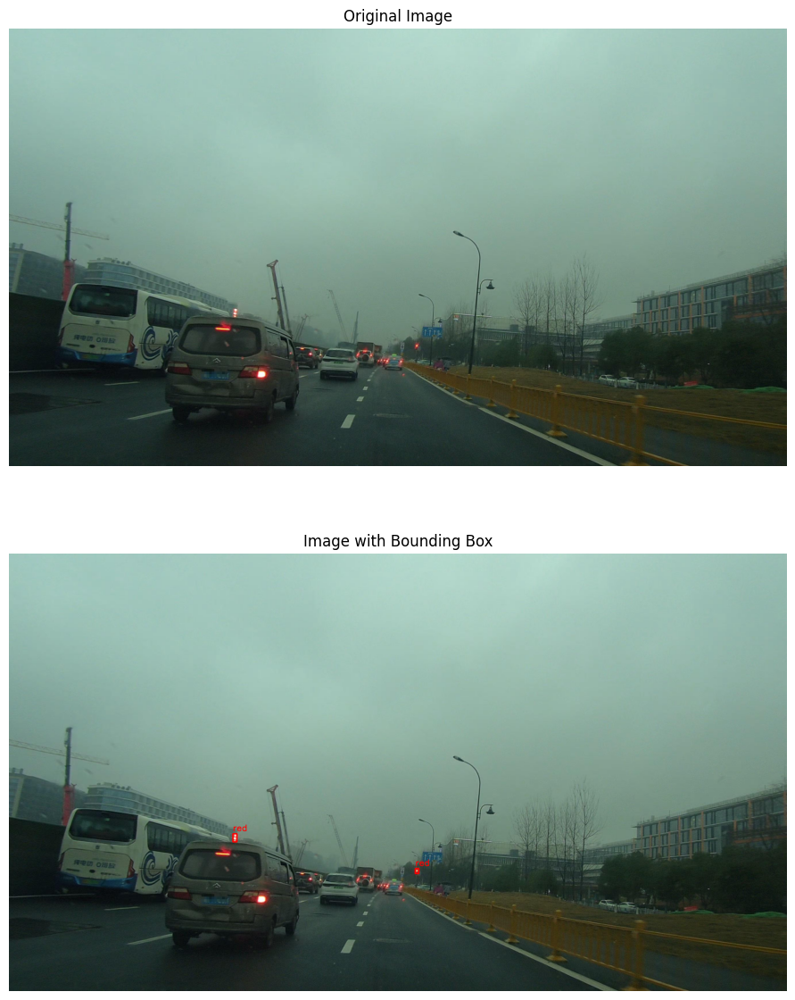

In [14]:
plot_img("02068.jpg", test_path, df)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..255.0].


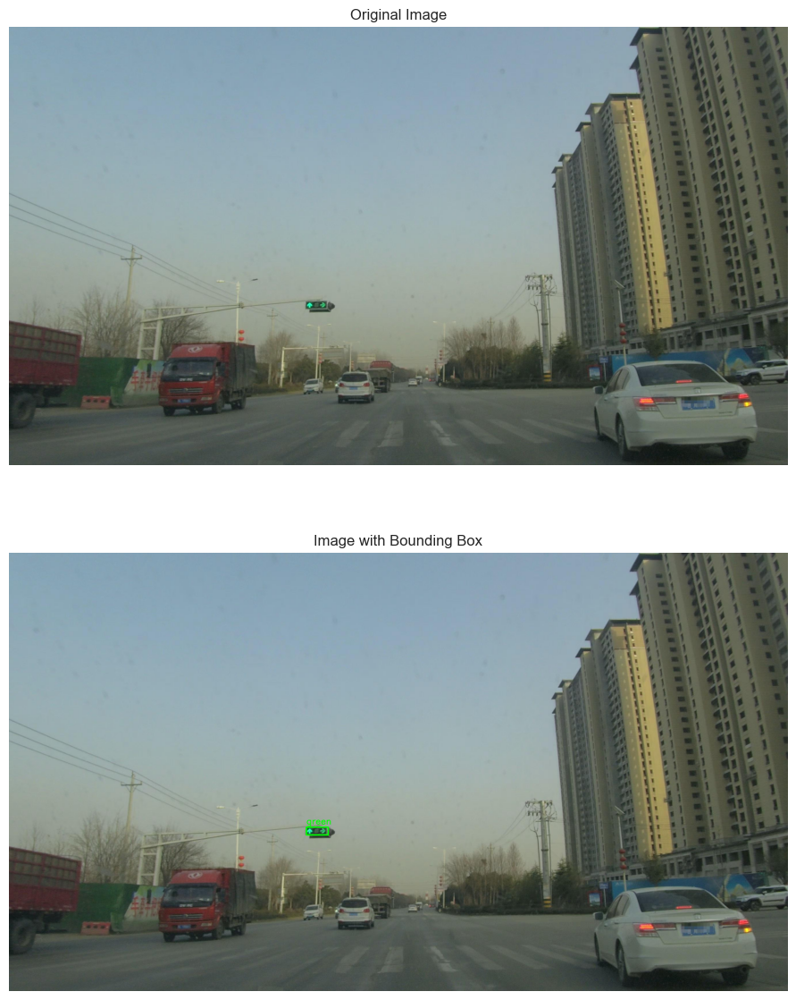

In [78]:
plot_img("02975.jpg", test_path, df)

In [ ]:
plot_img("02975.jpg", test_path, df)

Inference: 100%|██████████| 247/247 [38:38<00:00,  9.39s/it]


DETECTION PERFORMANCE METRICS
        Precision  Recall     F1     AP
backgr      0.000   0.000  0.000  0.000
red         0.555   0.874  0.679  0.855
green       0.551   0.871  0.675  0.855
yellow      0.471   0.821  0.598  0.769
ERROR MATRIX (TP / FP / FN)
         TP   FP   FN
backgr    0    0    0
red     891  715  128
green   671  546   99
yellow   32   36    7
mAP@0.5: 0.6198


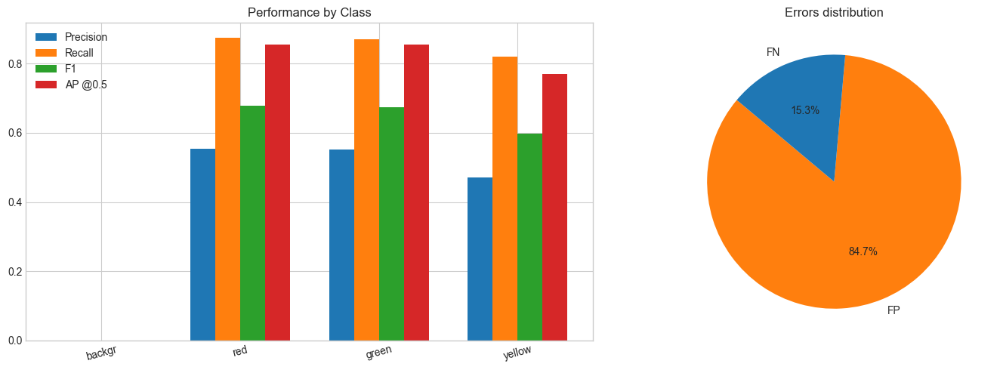

In [61]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from tqdm import tqdm
from torchvision.ops import box_iou

def calculate_ap_every_point(recalls, precisions):
    """Вычисление AP через интеграцию площади под PR-кривой со сглаживанием"""
    mrec = np.concatenate(([0.0], recalls, [1.0]))
    mpre = np.concatenate(([0.0], precisions, [0.0]))

    for i in range(len(mpre) - 2, -1, -1):
        mpre[i] = np.maximum(mpre[i], mpre[i + 1])

    i = np.where(mrec[1:] != mrec[:-1])[0]
    ap = np.sum((mrec[i + 1] - mrec[i]) * mpre[i + 1])
    return ap

def calculate_metrics(all_preds, all_targets, iou_thr=0.5):
    """Расчет метрик для всех классов"""
    results = {}
    
    for class_id, class_name in int_to_class.items():
        if class_name == 'background':
            continue

        all_class_scores, all_class_tp, total_gt = [], [], 0

        for pred, target in zip(all_preds, all_targets):
            p_mask, t_mask = pred['labels'] == class_id, target['labels'] == class_id
            p_boxes, p_scores = pred['boxes'][p_mask], pred['scores'][p_mask]
            t_boxes = target['boxes'][t_mask]
            
            total_gt += len(t_boxes)
            if len(p_boxes) == 0:
                continue

            indices = torch.argsort(p_scores, descending=True)
            p_boxes, p_scores = p_boxes[indices], p_scores[indices]

            if len(t_boxes) == 0:
                for s in p_scores:
                    all_class_tp.append(0)
                    all_class_scores.append(s.item())
                continue

            iou_matrix = box_iou(p_boxes, t_boxes)
            matched_gt = torch.zeros(len(t_boxes), dtype=torch.bool)

            for i in range(len(p_boxes)):
                best_iou, best_gt = iou_matrix[i].max(0)
                if best_iou >= iou_thr and not matched_gt[best_gt]:
                    all_class_tp.append(1)
                    matched_gt[best_gt] = True
                else:
                    all_class_tp.append(0)
                all_class_scores.append(p_scores[i].item())

        if total_gt == 0 or not all_class_scores:
            ap, prec, rec = 0.0, 0.0, 0.0
        else:
            scores_array, tp_array = np.array(all_class_scores), np.array(all_class_tp)
            indices = np.argsort(-scores_array)
            tp_sorted = tp_array[indices]
            tp_cum, fp_cum = np.cumsum(tp_sorted), np.cumsum(1 - tp_sorted)

            recalls = tp_cum / total_gt
            precisions = tp_cum / (tp_cum + fp_cum)
            ap = calculate_ap_every_point(recalls, precisions)
            prec, rec = precisions[-1], recalls[-1]

        results[class_name] = {
            'Precision': round(float(prec), 3),
            'Recall': round(float(rec), 3),
            'F1': round(float(2*prec*rec/(prec+rec) if prec+rec>0 else 0), 3),
            'AP': round(float(ap), 3),
            'TP': int(np.sum(all_class_tp)),
            'FP': int(len(all_class_tp) - np.sum(all_class_tp)),
            'FN': int(total_gt - np.sum(all_class_tp))
        }
    return results

def print_summary(metrics):
    """Вывод таблиц метрик и матрицы ошибок"""
    print("DETECTION PERFORMANCE METRICS")
    df_metrics = pd.DataFrame.from_dict(metrics, orient='index')
    print(df_metrics[['Precision', 'Recall', 'F1', 'AP']])
    
    print("ERROR MATRIX (TP / FP / FN)")
    print(df_metrics[['TP', 'FP', 'FN']])
    
    mAP = np.mean([m['AP'] for m in metrics.values()])
    print(f"mAP@0.5: {mAP:.4f}")

def plot_results(metrics):
    """Визуализация результатов"""
    classes = list(metrics.keys())
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
    x, width = np.arange(len(classes)), 0.18

    ax1.bar(x - 1.5*width, [metrics[c]['Precision'] for c in classes], width, label='Precision', color='C0')
    ax1.bar(x - 0.5*width, [metrics[c]['Recall'] for c in classes], width, label='Recall', color='C1')
    ax1.bar(x + 0.5*width, [metrics[c]['F1'] for c in classes], width, label='F1', color='C2')
    ax1.bar(x + 1.5*width, [metrics[c]['AP'] for c in classes], width, label='AP @0.5', color='C3')
    ax1.set_title('Performance by Class')
    ax1.set_xticks(x)
    ax1.set_xticklabels(classes, rotation=15)
    ax1.legend()

    ax2.pie([sum(m['FP'] for m in metrics.values()), sum(m['FN'] for m in metrics.values())], 
            labels=['FP', 'FN'], autopct='%1.1f%%', colors=['#ff7f0e', '#1f77b4'], startangle=140)
    ax2.set_title('Errors distribution')
    plt.tight_layout()
    plt.show()

def quick_evaluation(model, loader, device):
    """Основной процесс оценки"""
    model.eval()
    all_preds, all_targets = [], []
    with torch.no_grad():
        for images, targets, _ in tqdm(loader, desc="Inference"):
            images = [img.to(device) for img in images]
            outputs = model(images)
            all_preds.extend([{k: v.cpu() for k, v in out.items()} for out in outputs])
            all_targets.extend([{k: v.cpu() for k, v in t.items()} for t in targets])

    metrics = calculate_metrics(all_preds, all_targets)
    print_summary(metrics)
    plot_results(metrics)
    return metrics

# Запуск оценки
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)
metrics = quick_evaluation(model, valid_data_loader, device)

In [29]:
import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import FasterRCNNBoxScoreTarget
from pytorch_grad_cam.utils.image import show_cam_on_image


def fasterrcnn_reshape_transform(x):
    if isinstance(x, dict):
        return x['0']
    return x

device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
model = torchvision.models.detection.fasterrcnn_resnet50_fpn(weights=None)
num_classes = 4 
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)

checkpoint = torch.load("model_9.pth", map_location=device)
model.load_state_dict(checkpoint['model_state_dict'])
model.to(device)
model.eval()


target_layers = [model.backbone.body.layer4]

cam = GradCAM(model=model,
              target_layers=target_layers,
              reshape_transform=fasterrcnn_reshape_transform)

def explain_prediction(dataset_index):
    image, targets, image_name = valid_dataset[dataset_index]
    input_tensor = image.to(device).unsqueeze(0)

    outputs = model(input_tensor)
    res = outputs[0]

    if len(res['boxes']) > 0:
        # Берем первый (самый уверенный) объект
        idx = 0
        box = res['boxes'][idx].detach().cpu().numpy()
        label = res['labels'][idx].item()
        score = res['scores'][idx].item()

        # Создаем цель для Grad-CAM (конкретный бокс и его класс)
        cam_targets = [FasterRCNNBoxScoreTarget(labels=[label], bounding_boxes=[box])]

        # Генерируем маску важности пикселей
        grayscale_cam = cam(input_tensor=input_tensor, targets=cam_targets)
        grayscale_cam = grayscale_cam[0, :]

        # Готовим оригинальное фото
        rgb_img = image.permute(1, 2, 0).cpu().numpy()
        rgb_img = np.clip(rgb_img, 0, 1)

        # Накладываем тепловую карту на фото
        visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

        # Вывод результата
        plt.figure(figsize=(15, 7))
        
        # Оригинальное фото
        plt.subplot(1, 2, 1)
        plt.imshow(rgb_img)
        plt.title(f"Original: {image_name}")
        plt.axis('off')

        # Модифицированное фото (Attention Map)
        plt.subplot(1, 2, 2)
        plt.imshow(visualization)
        
        plt.title(f"Attention Map")
        plt.axis('off')
        
        plt.show()
    else:
        print(f"Объекты на снимке {image_name} не найдены.")


C:\Users\admin\AppData\Local\Temp\ipykernel_14148\1001563428.py:22: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load("model_9.pth", map_location=device)

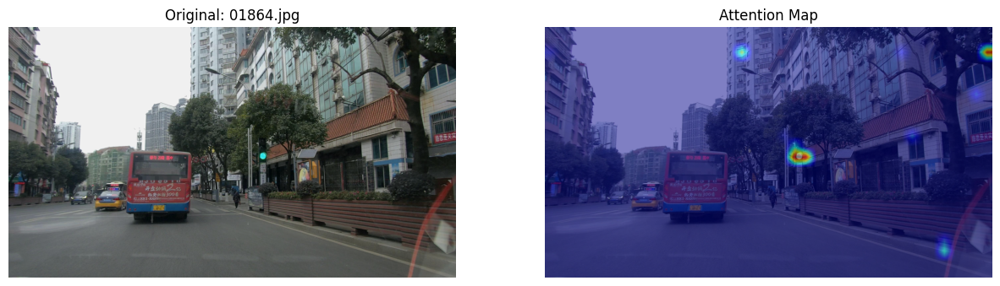

In [30]:
explain_prediction(22)

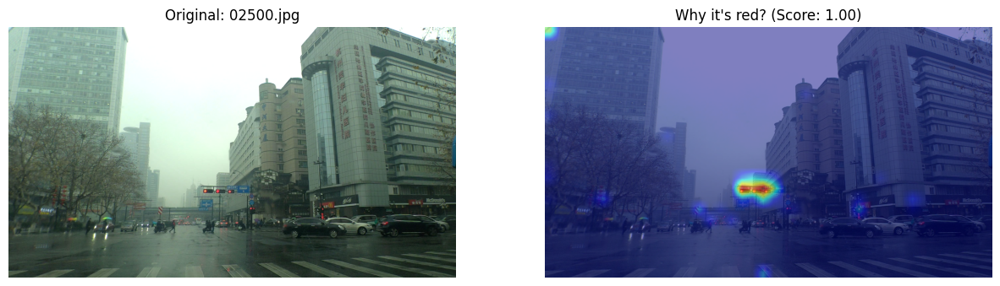

In [23]:
explain_prediction(25)

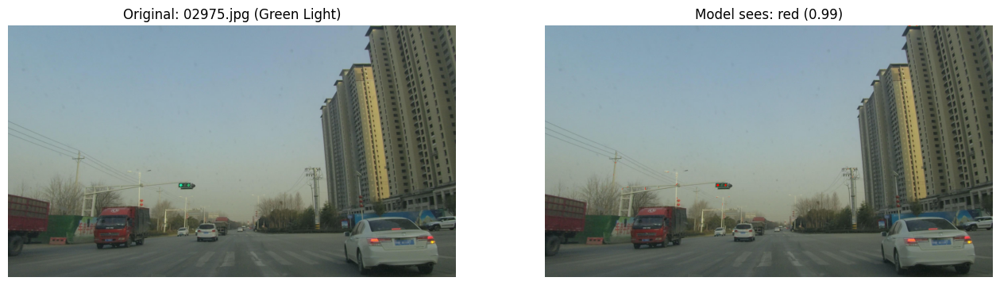

In [ ]:
import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
import os

def test_color_swap(image_name, target_color='red'):
    # 1. Загрузка оригинала (путь берем из вашего train_path)
    img_path = os.path.join(test_path, image_name)
    image_bgr = cv2.imread(img_path)
    if image_bgr is None:
        print("Файл не найден!")
        return
        
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    
    # 2. Поиск зеленого цвета (активной линзы) через HSV
    hsv = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2HSV)
    
    # Диапазон зеленого
    lower_green = np.array([40, 40, 150]) 
    upper_green = np.array([90, 255, 255])
    
    mask = cv2.inRange(hsv, lower_green, upper_green)
    
    # 3. Создаем модифицированное изображение
    hacked_img = image_rgb.copy()
    if target_color == 'red':
        hacked_img[mask > 0] = [255, 0, 0] 
        
    model.eval()
    input_tensor = (torch.from_numpy(hacked_img).permute(2, 0, 1).float() / 255.0).to(device).unsqueeze(0)
    
    with torch.no_grad():
        prediction = model(input_tensor)[0]
    
    fig, ax = plt.subplots(1, 2, figsize=(16, 8))
    
    ax[0].imshow(image_rgb)
    ax[0].set_title(f"Original: {image_name} (Green Light)")
    ax[0].axis('off')
    
    ax[1].imshow(hacked_img)
    if len(prediction['labels']) > 0:
        label_idx = prediction['labels'][0].item()
        score = prediction['scores'][0].item()
        label_name = int_to_class[label_idx]
        ax[1].set_title(f"Model sees: {label_name} ({score:.2f})")
    else:
        ax[1].set_title("Model detected nothing")
    ax[1].axis('off')
    
    plt.show()

test_color_swap("02975.jpg")

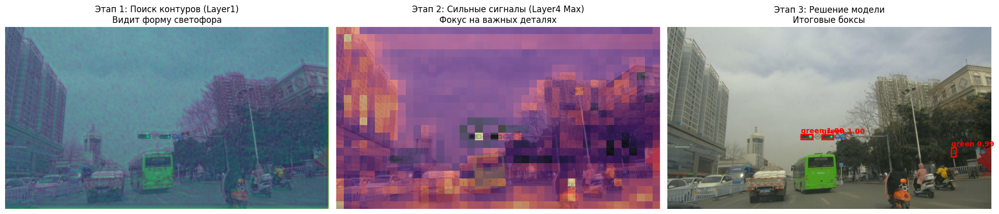

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import cv2
import torchvision.transforms as T

def visualize_model_insight(model, filename, test_path):
    model.eval()
    device = next(model.parameters()).device
    
    img_path = os.path.join(test_path, filename)
    image = cv2.imread(img_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
    
    h, w, _ = image.shape
    image_resized = cv2.resize(image, (int(w*0.5), int(h*0.5)))
    input_tensor = T.ToTensor()(image_resized).to(device).unsqueeze(0)

    activations = {}
    def get_hook(name):
        def hook(m, i, o):
            if isinstance(o, dict): activations[name] = o['0'].detach()
            else: activations[name] = o.detach()
        return hook

    h1 = model.backbone.body.layer1.register_forward_hook(get_hook('early'))
    h2 = model.backbone.body.layer4.register_forward_hook(get_hook('deep'))

    with torch.no_grad():
        model(input_tensor)
    h1.remove(); h2.remove()

    early_map = torch.mean(activations['early'][0], dim=0).cpu().numpy()
    
    deep_map_max, _ = torch.max(activations['deep'][0], dim=0)
    deep_map_max = deep_map_max.cpu().numpy()

    fig, axes = plt.subplots(1, 3, figsize=(20, 7))
    
    axes[0].imshow(image_resized)
    axes[0].imshow(early_map, cmap='viridis', alpha=0.6, extent=(0, int(w*0.5), int(h*0.5), 0))
    axes[0].set_title("Этап 1: Поиск контуров (Layer1)\nВидит форму светофора")
    axes[0].axis('off')


    axes[1].imshow(image_resized)
    axes[1].imshow(deep_map_max, cmap='magma', alpha=0.6, extent=(0, int(w*0.5), int(h*0.5), 0))
    axes[1].set_title("Этап 2: Сильные сигналы (Layer4 Max)\nФокус на важных деталях")
    axes[1].axis('off')

    model.eval()
    with torch.no_grad():
        prediction = model(input_tensor)[0]
    
    axes[2].imshow(image_resized)
    for box, score, label in zip(prediction['boxes'], prediction['scores'], prediction['labels']):
        if score > 0.5:
            b = box.cpu().numpy()
            axes[2].add_patch(plt.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1], fill=False, color='red', lw=2))
            axes[2].text(b[0], b[1]-5, f"{int_to_class[label.item()]} {score:.2f}", color='red', fontsize=10, weight='bold')
    axes[2].set_title("Этап 3: Решение модели\nИтоговые боксы")
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()

visualize_model_insight(model, "02956.jpg", test_path)

In [19]:
def analyze_thresholds(model, test_loader, device):
    all_scores = []
    
    model.eval()
    with torch.no_grad():
        for images, targets, _ in test_loader:
            images = [img.to(device) for img in images]
            outputs = model(images)
            
            for out in outputs:
                all_scores.extend(out['scores'].cpu().numpy())
    
    plt.figure(figsize=(10, 5))
    plt.hist(all_scores, bins=50, color='skyblue', edgecolor='black')
    plt.axvline(x=0.5, color='red', linestyle='--', label='Стандартный порог (0.5)')
    plt.title("Распределение уверенности (Scores) предсказаний")
    plt.xlabel("Confidence Score")
    plt.ylabel("Количество боксов")
    plt.legend()
    plt.show()
    
    print(f"Средняя уверенность модели: {np.mean(all_scores):.2f}")
    print(f"Пограничное значение (медиана): {np.median(all_scores):.2f}")

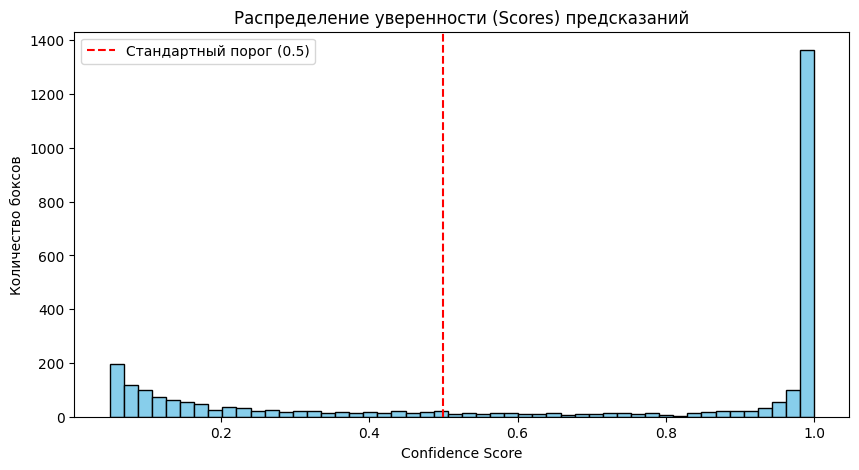

Средняя уверенность модели: 0.68
Пограничное значение (медиана): 0.97


In [20]:
analyze_thresholds(model, valid_data_loader, device)

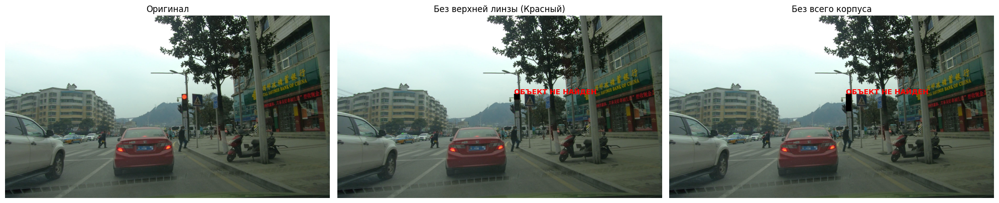

In [ ]:
def quantitative_analysis_with_boxes(model, image_path, device, transform, int_to_class):
    model.eval()
    
    image_raw = Image.open(image_path).convert("RGB")
    image_tensor = transform(image_raw).to(device)
    
    with torch.no_grad():
        base_out = model([image_tensor])[0]
    
    if len(base_out['boxes']) == 0:
        print("Объекты не найдены")
        return

    box = base_out['boxes'][0].cpu().numpy()
    x1, y1, x2, y2 = box.astype(int)
    height = y2 - y1

    zones = {
        "Оригинал": None,
        "Без верхней линзы (Красный)": (x1, y1, x2, int(y1 + 1/3 * height)),
        "Без всего корпуса": (x1, y1, x2, y2)
    }

    plt.figure(figsize=(20, 7))

    for i, (name, zone) in enumerate(zones.items()):
        modified_tensor = image_tensor.clone()
        if zone:
            zx1, zy1, zx2, zy2 = zone
            modified_tensor[:, zy1:zy2, zx1:zx2] = 0
        
        with torch.no_grad():
            output = model([modified_tensor])[0]
        
        img_viz = modified_tensor.permute(1, 2, 0).cpu().numpy()
        img_viz = np.clip(img_viz, 0, 1)
        
        ax = plt.subplot(1, 3, i + 1)
        ax.imshow(img_viz)
        
        if len(output['boxes']) > 0:
            b = output['boxes'][0].cpu().numpy()
            l = output['labels'][0].item()
            s = output['scores'][0].item()
            
            # Рисуем рамку
            rect = plt.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1], 
                                 fill=False, color='lime', linewidth=3)
            ax.add_patch(rect)
            
            # # Добавляем текст (Класс + Уверенность)
            # label_text = f"{int_to_class.get(l, l)}: {s:.2f}"
            # ax.text(b[0], b[1]-10, "kjfv", color='lime', 
            #         fontsize=12, fontweight='bold', backgroundcolor='black')
        else:
            ax.text(x1, y1, "ОБЪЕКТ НЕ НАЙДЕН", color='red', fontweight='bold')

        ax.set_title(f"{name}")
        ax.axis('off')

    plt.tight_layout()
    plt.show()


quantitative_analysis_with_boxes(model, "C:/Users/admin/Downloads/archive/test_dataset/test_images/01518.jpg", device, data_transform, int_to_class)